# Visualization of the final radiomic features

Figures for the statistics in `statistics.ipynb`: feature counts, distributions, univariate tests, variance
sources, relations among feature classes and filters, and multivariate structure (clustering, PCA, classification).
The statistics are recomputed here, so this notebook can be run on its own. Figures are saved in `FIGURE_DIR`.

In [1]:
import sys
from pathlib import Path

CODE_ROOT = Path("/Users/kamleshranabhat/Desktop/radiomics/full_pipeline")
for folder in ["", "scripts", "post_processing", "feature_analysis"]:
    if str(CODE_ROOT / folder) not in sys.path:
        sys.path.insert(0, str(CODE_ROOT / folder))

import pandas as pd
from IPython.display import display
from stat_and_viz import *

FEATURE_DIR = Path("/Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs/features/final")
FIGURE_DIR = Path("/Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs/figures/feature_analysis")

ALPHA = 0.05
set_plot_style()

In [2]:
table, info = load_final_features(FEATURE_DIR)

11 filters | 40 samples | 2254 features


## 1. Feature selection overview

Extracted → reproducible → selected features per filter

saved /Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs/figures/feature_analysis/selection_funnel.png


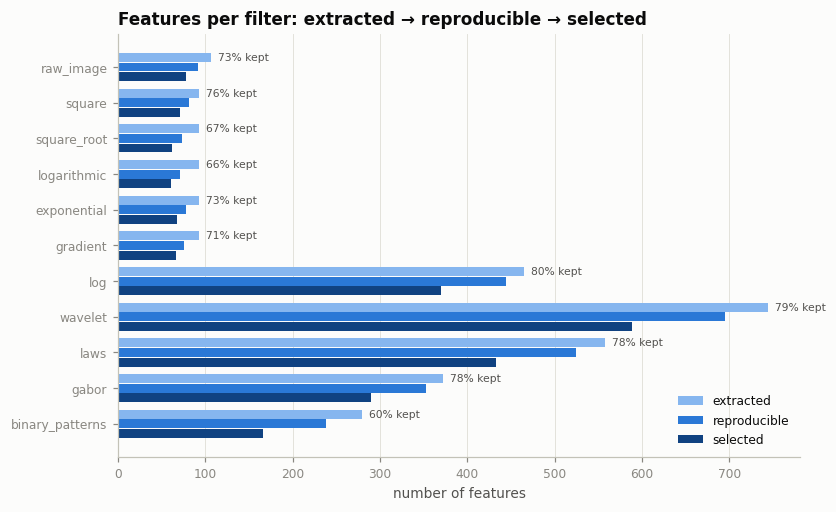

In [3]:
fig = plot_selection_funnel(selection_counts(FEATURE_DIR))
save_figure(fig, FIGURE_DIR / "selection_funnel.png")

Final features per filter and feature class

saved /Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs/figures/feature_analysis/features_per_filter_and_class.png


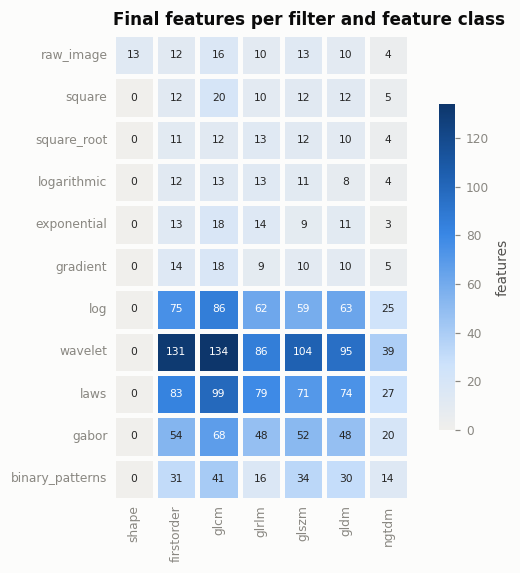

In [4]:
fig = plot_count_heatmap(count_by_filter_and_class(info))
save_figure(fig, FIGURE_DIR / "features_per_filter_and_class.png")

## 2. Distributions

Normality, skewness and coefficient of variation per filter

saved /Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs/figures/feature_analysis/descriptive_overview.png


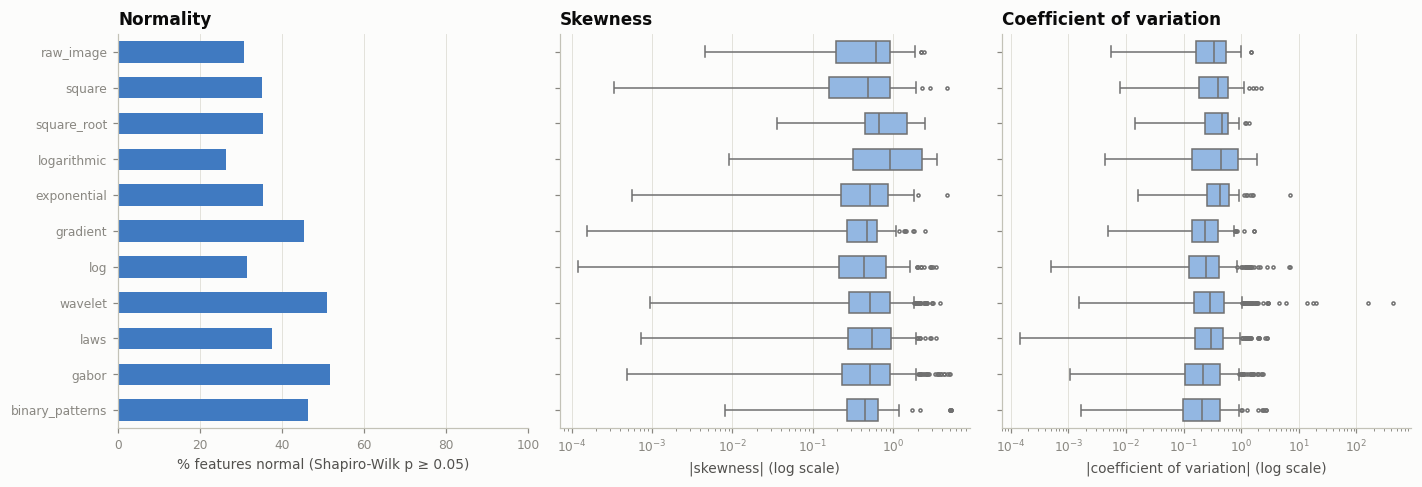

In [5]:
desc = descriptive_statistics(table, info)
fig = plot_descriptive_overview(desc)
save_figure(fig, FIGURE_DIR / "descriptive_overview.png")

## 3. Univariate analysis: MRI channels

Friedman test of every feature (blocks = breast)

In [6]:
channel_results = repeated_measures_test(table, info, group="channel", block=["case", "side"], alpha=ALPHA)

channel: 253 of 2241 tested features differ (q < 0.05)


Effect size (Kendall's W) against significance, colored by feature class

saved /Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs/figures/feature_analysis/volcano_channel.png


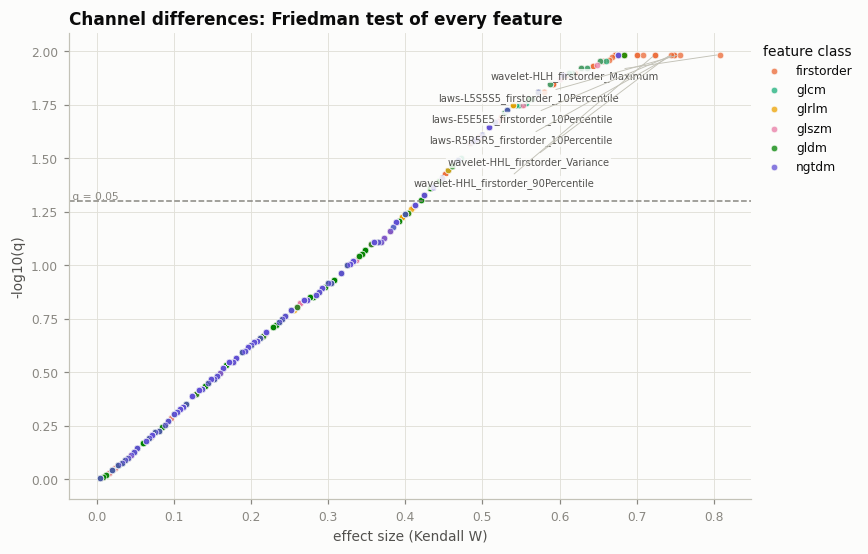

In [7]:
fig = plot_volcano(channel_results, alpha=ALPHA, title="Channel differences: Friedman test of every feature")
save_figure(fig, FIGURE_DIR / "volcano_channel.png")

% of features that differ between channels, per filter and feature class

saved /Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs/figures/feature_analysis/significance_channel.png


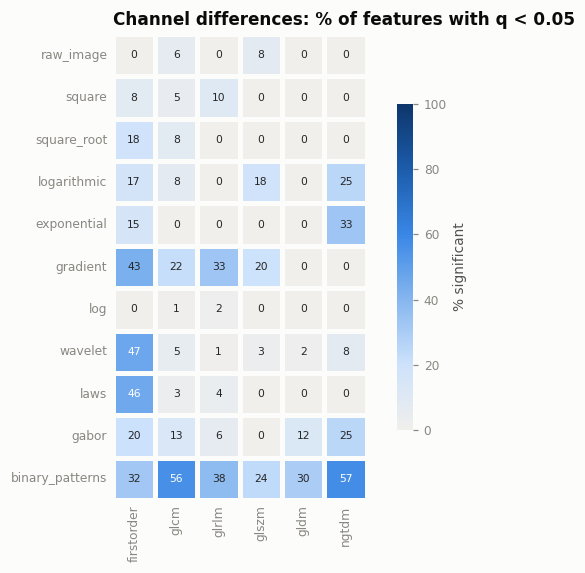

In [8]:
fig = plot_significance_heatmap(channel_results, title=f"Channel differences: % of features with q < {ALPHA}")
save_figure(fig, FIGURE_DIR / "significance_channel.png")

The 6 most channel-dependent features (gray lines connect the 4 channels of the same breast)

saved /Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs/figures/feature_analysis/top_features_channel.png


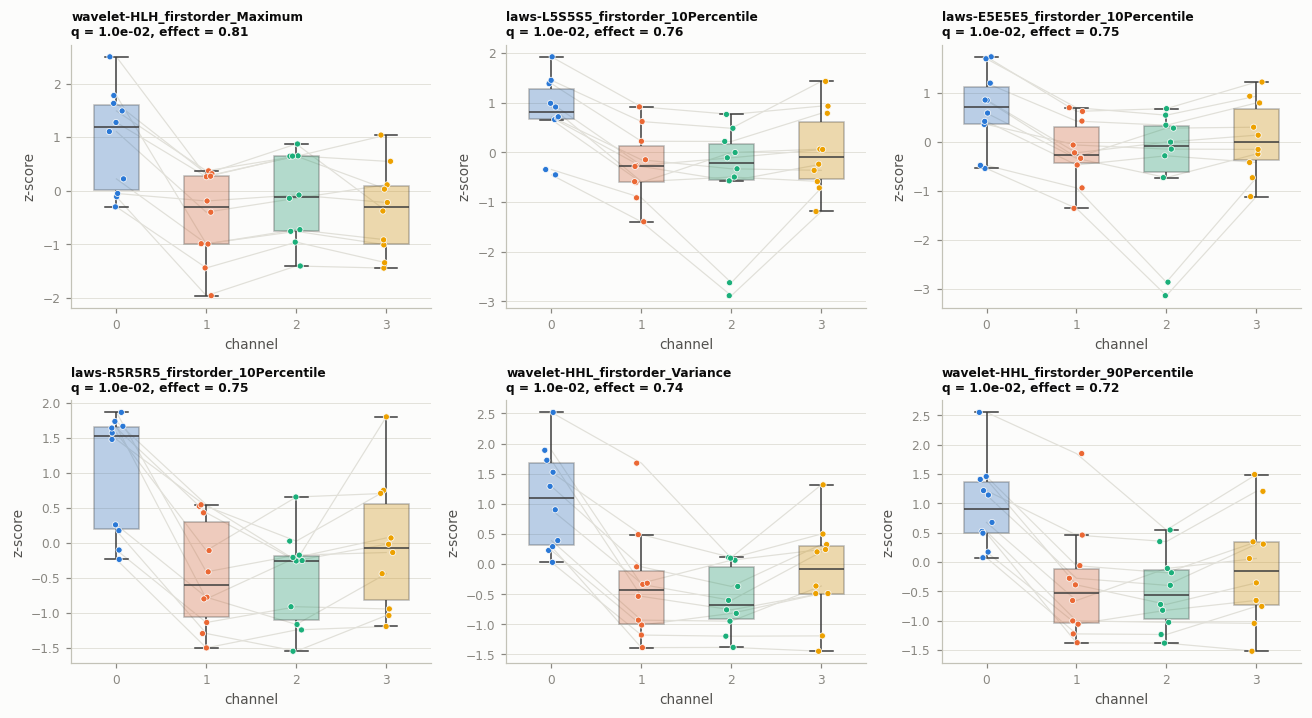

In [9]:
fig = plot_top_features(table, channel_results, group="channel", block=["case", "side"], n=6)
save_figure(fig, FIGURE_DIR / "top_features_channel.png")

## 4. Univariate analysis: left vs right breast

Wilcoxon signed-rank test (pairs = case + channel), shape features excluded

In [10]:
info_no_shape = info[info["feature_class"] != "shape"]
side_results = repeated_measures_test(table, info_no_shape, group="side", block=["case", "channel"], alpha=ALPHA)

side: 307 of 2241 tested features differ (q < 0.05)


saved /Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs/figures/feature_analysis/volcano_side.png


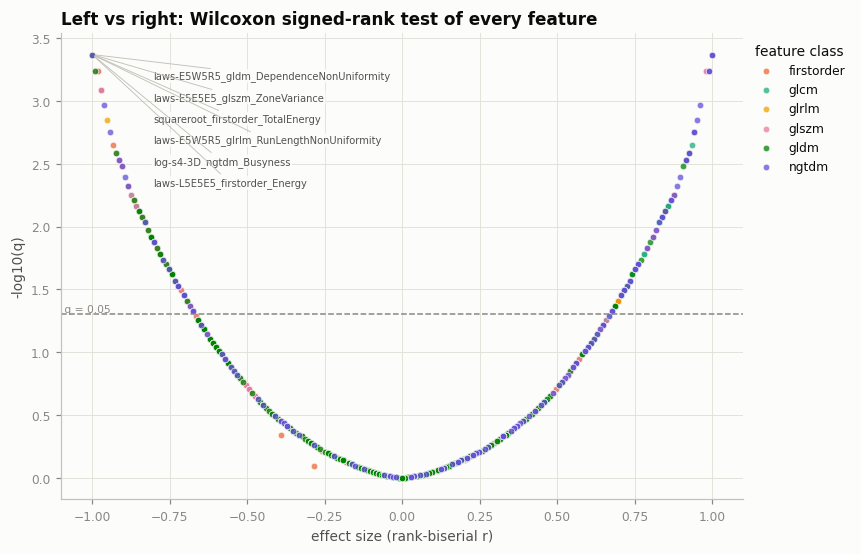

In [11]:
fig = plot_volcano(side_results, alpha=ALPHA, title="Left vs right: Wilcoxon signed-rank test of every feature")
save_figure(fig, FIGURE_DIR / "volcano_side.png")

saved /Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs/figures/feature_analysis/significance_side.png


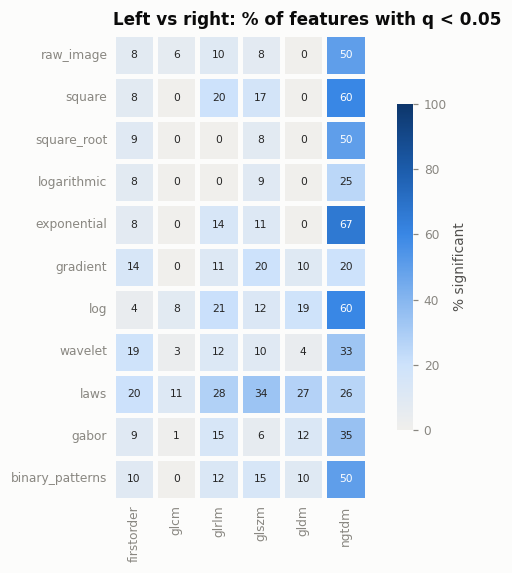

In [12]:
fig = plot_significance_heatmap(side_results, title=f"Left vs right: % of features with q < {ALPHA}")
save_figure(fig, FIGURE_DIR / "significance_side.png")

saved /Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs/figures/feature_analysis/top_features_side.png


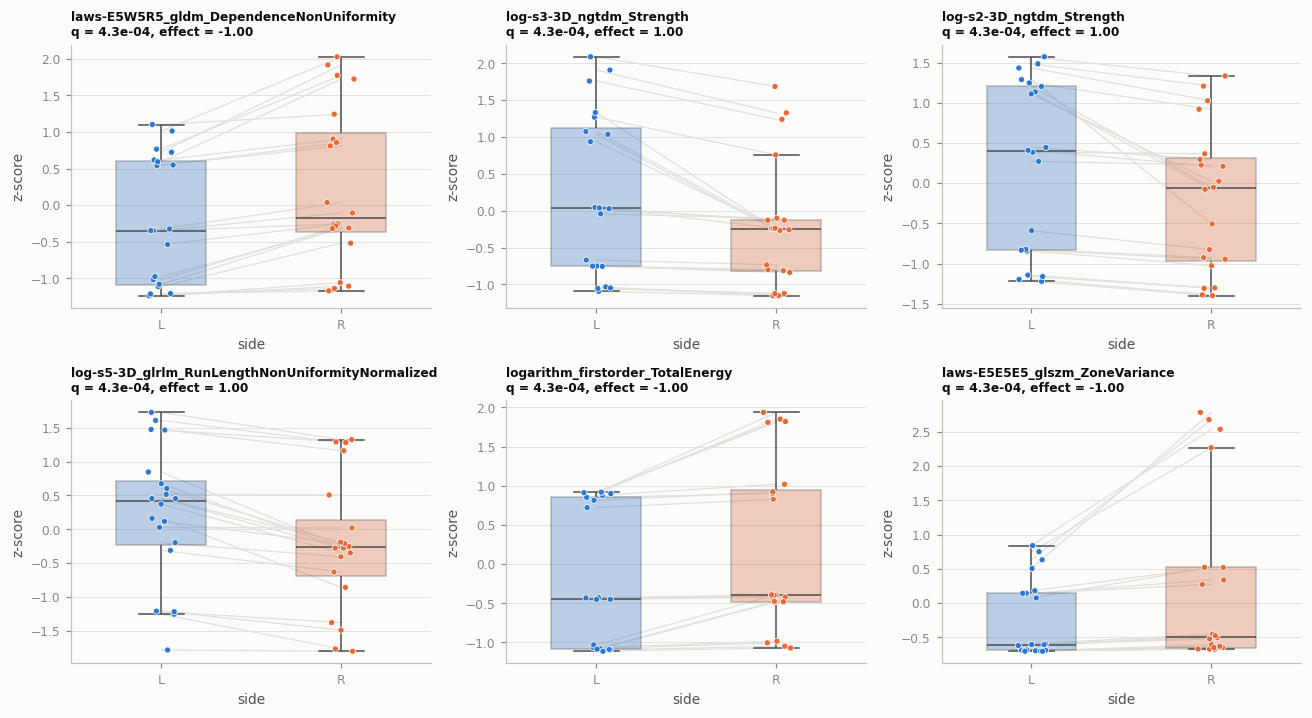

In [13]:
fig = plot_top_features(table, side_results, group="side", block=["case", "channel"], n=6)
save_figure(fig, FIGURE_DIR / "top_features_side.png")

## 5. Sources of variance

Mean share of feature variance explained by patient, side, channel and residual

saved /Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs/figures/feature_analysis/variance_components_filter.png


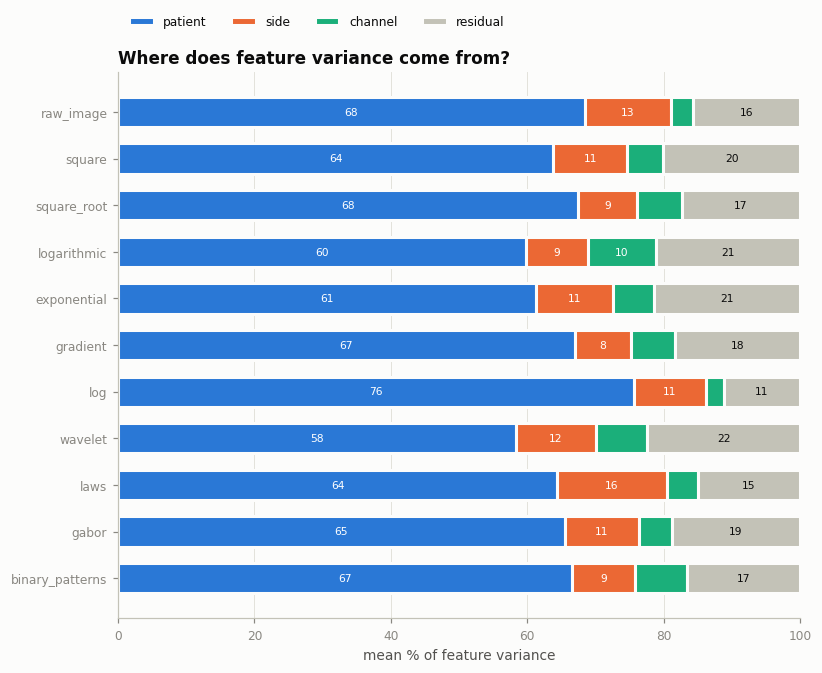

In [14]:
variance = variance_components(table, info)
fig = plot_variance_components(variance, by="filter")
save_figure(fig, FIGURE_DIR / "variance_components_filter.png")

saved /Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs/figures/feature_analysis/variance_components_class.png


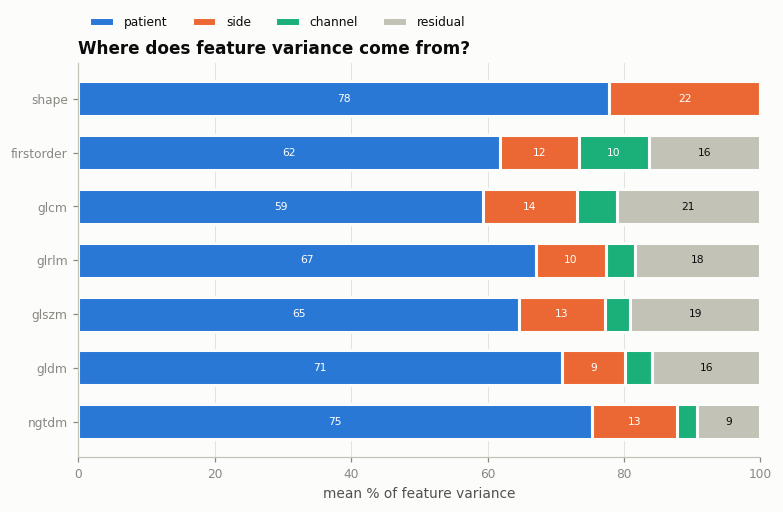

In [15]:
fig = plot_variance_components(variance, by="feature_class")
save_figure(fig, FIGURE_DIR / "variance_components_class.png")

## 6. Relation among feature classes

Mean |Spearman rho| between classes

saved /Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs/figures/feature_analysis/class_association_rho.png


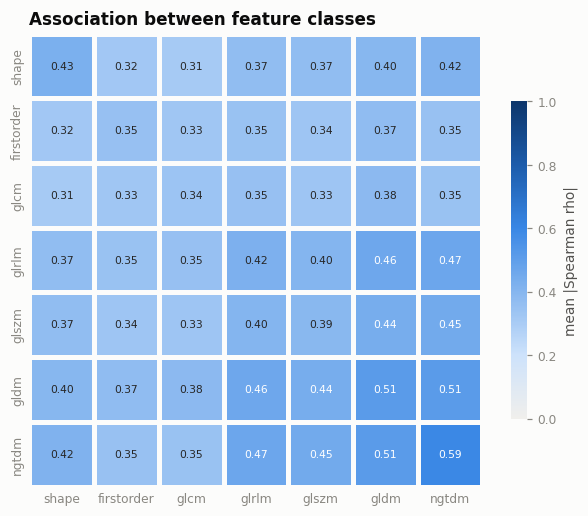

In [16]:
fig = plot_association_heatmap(mean_abs_spearman(table, info, by="feature_class"), "Association between feature classes")
save_figure(fig, FIGURE_DIR / "class_association_rho.png")

Modified RV coefficient between classes

saved /Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs/figures/feature_analysis/class_association_rv.png


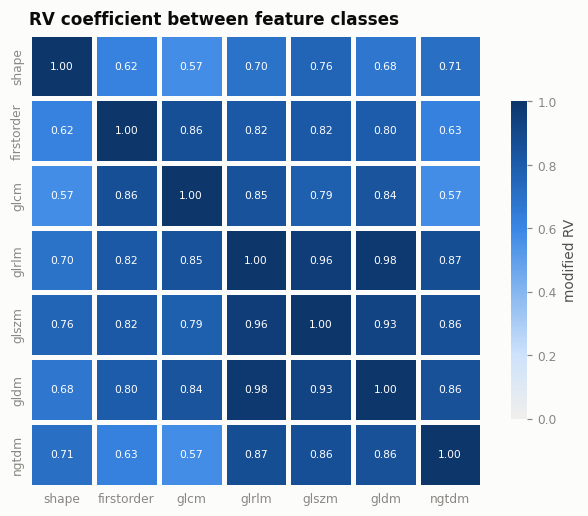

In [17]:
fig = plot_association_heatmap(rv_matrix(table, info, by="feature_class"), "RV coefficient between feature classes", label="modified RV")
save_figure(fig, FIGURE_DIR / "class_association_rv.png")

## 7. Relation among filters

Mean |Spearman rho| between filters

saved /Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs/figures/feature_analysis/filter_association_rho.png


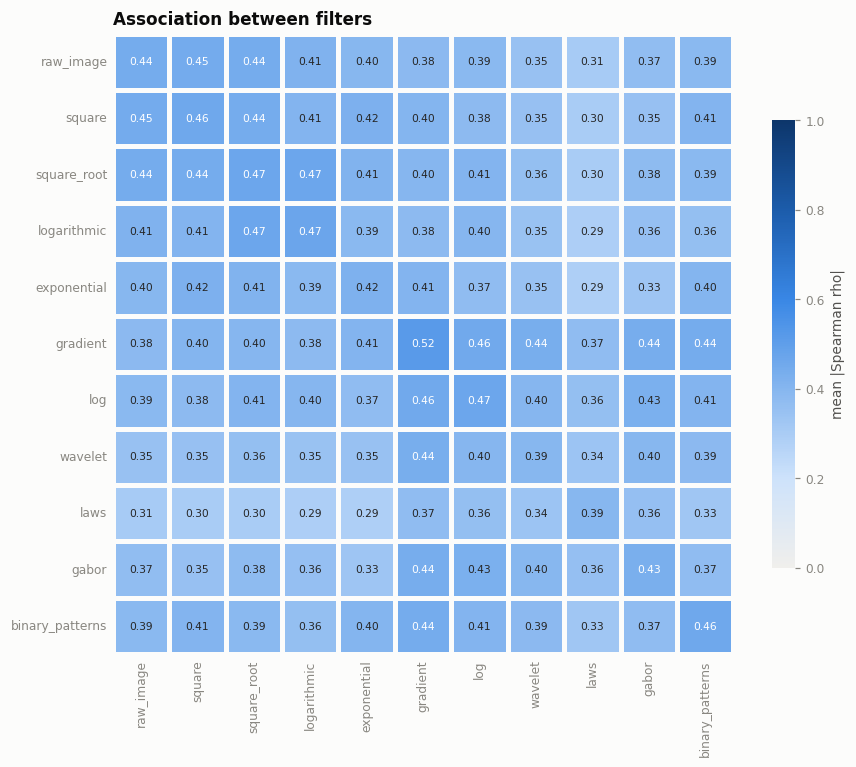

In [18]:
fig = plot_association_heatmap(mean_abs_spearman(table, info, by="filter"), "Association between filters")
save_figure(fig, FIGURE_DIR / "filter_association_rho.png")

Modified RV coefficient between filters

saved /Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs/figures/feature_analysis/filter_association_rv.png


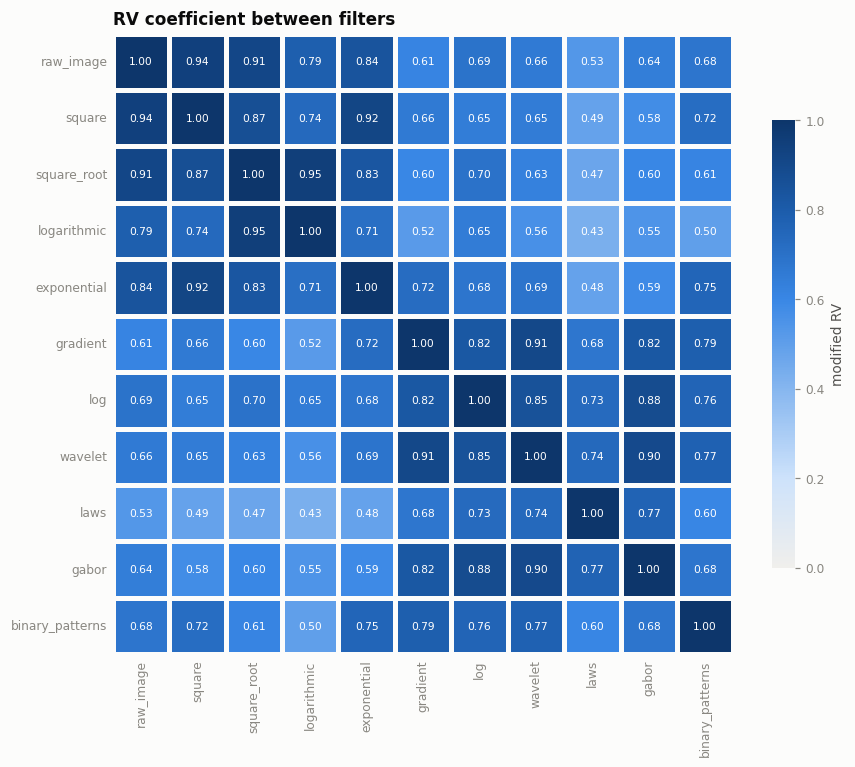

In [19]:
fig = plot_association_heatmap(rv_matrix(table, info, by="filter"), "RV coefficient between filters", label="modified RV")
save_figure(fig, FIGURE_DIR / "filter_association_rv.png")

## 8. Multivariate structure

Clustered heatmap of all samples × features (z-scores). Rows that cluster together are similar samples; the row bars
show if they cluster by channel, side or (from the row names) patient.

/opt/miniconda3/envs/cenv/lib/python3.12/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)
/opt/miniconda3/envs/cenv/lib/python3.12/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


saved /Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs/figures/feature_analysis/clustermap.png


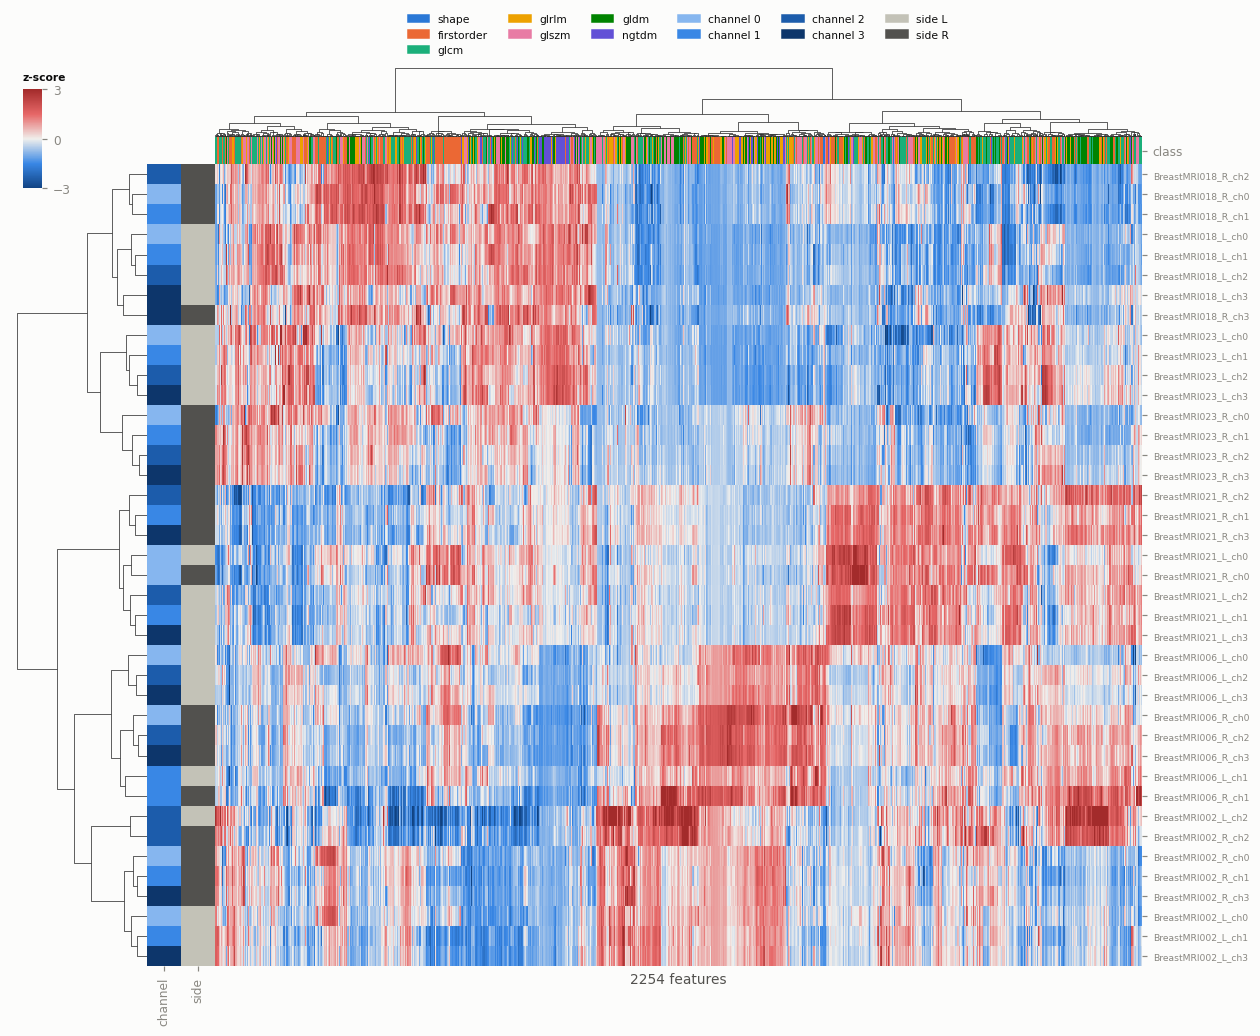

In [20]:
fig = plot_clustermap(table, info, row_groups=["channel", "side"])
save_figure(fig, FIGURE_DIR / "clustermap.png")

PCA: scree plot and scores colored by channel

saved /Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs/figures/feature_analysis/pca_channel.png


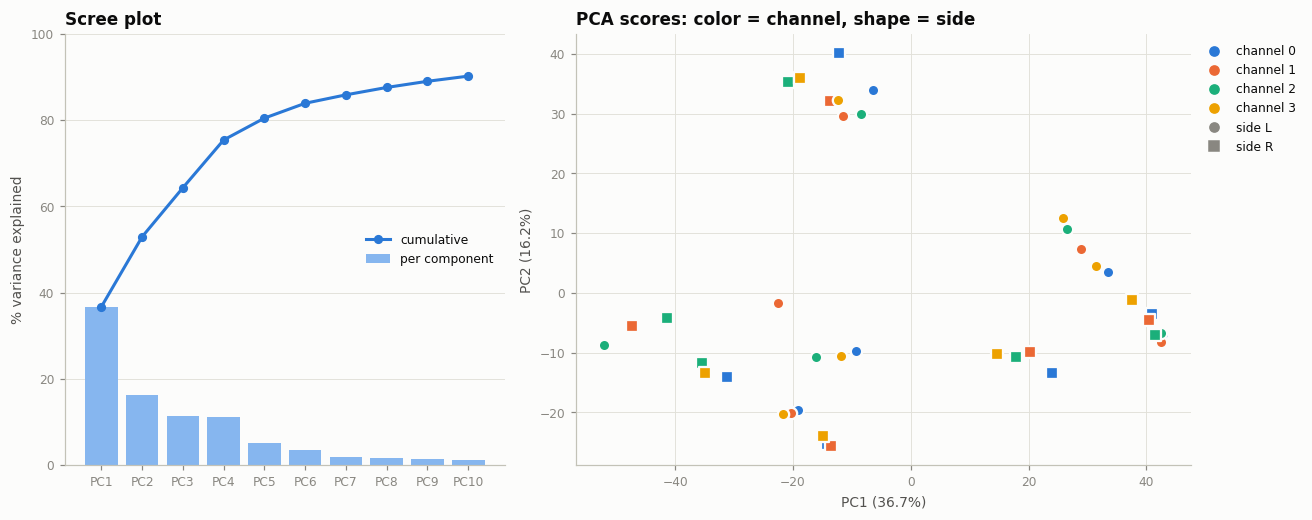

In [21]:
pca_scores, pca_explained, pca_loadings = run_pca(table, info, n_components=10)
fig = plot_pca(pca_scores, pca_explained, color_by="channel", marker_by="side")
save_figure(fig, FIGURE_DIR / "pca_channel.png")

PCA scores colored by patient

saved /Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs/figures/feature_analysis/pca_patient.png


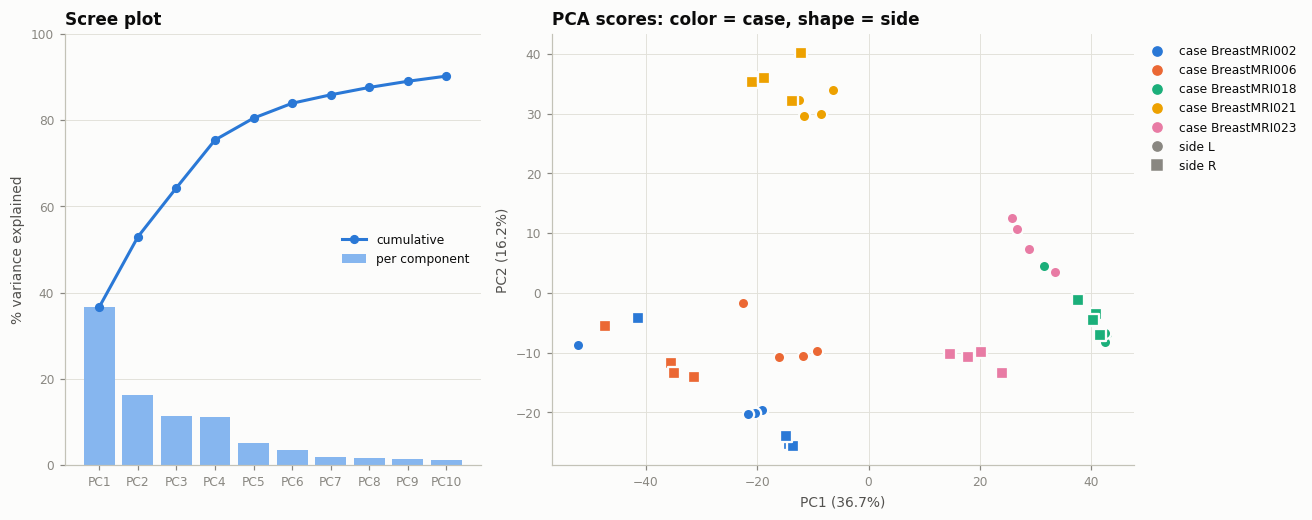

In [22]:
fig = plot_pca(pca_scores, pca_explained, color_by="case", marker_by="side")
save_figure(fig, FIGURE_DIR / "pca_patient.png")

Features that drive PC1 and PC2

saved /Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs/figures/feature_analysis/pca_loadings_pc1.png


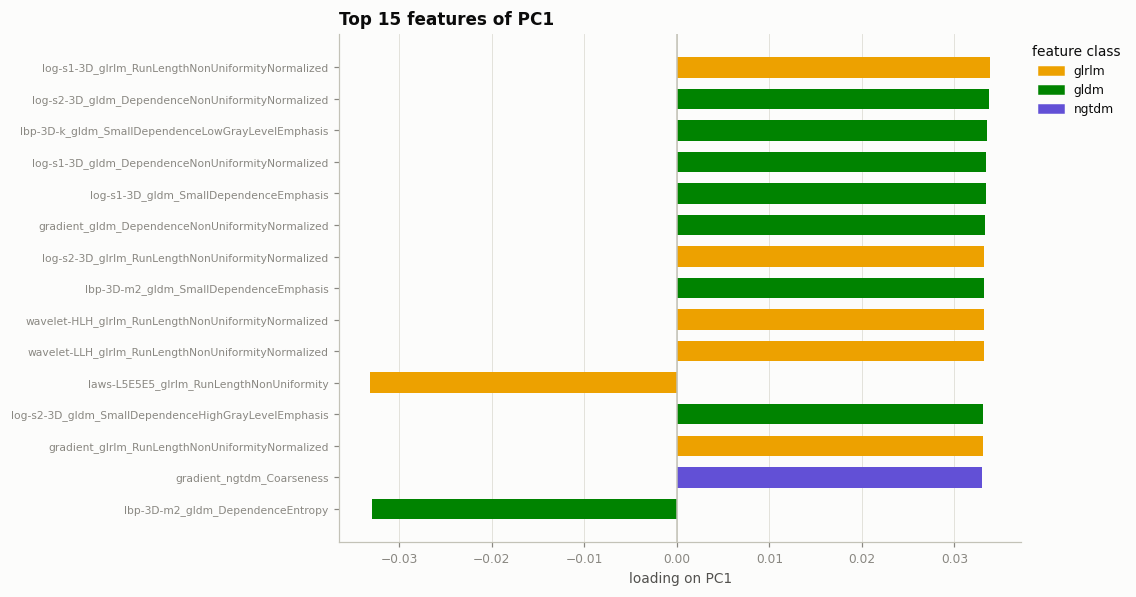

In [23]:
fig = plot_pca_loadings(pca_loadings, component="PC1", n=15)
save_figure(fig, FIGURE_DIR / "pca_loadings_pc1.png")

saved /Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs/figures/feature_analysis/pca_loadings_pc2.png


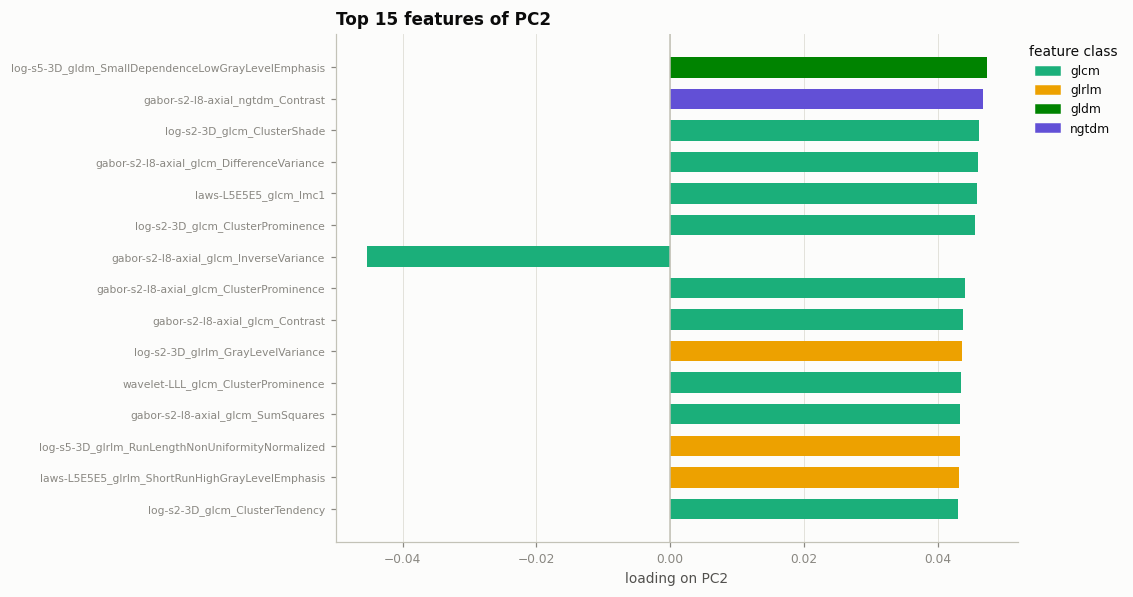

In [24]:
fig = plot_pca_loadings(pca_loadings, component="PC2", n=15)
save_figure(fig, FIGURE_DIR / "pca_loadings_pc2.png")

Cross-validated classification of the channel (leave-one-patient-out) against permuted labels

saved /Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs/figures/feature_analysis/classification_channel.png


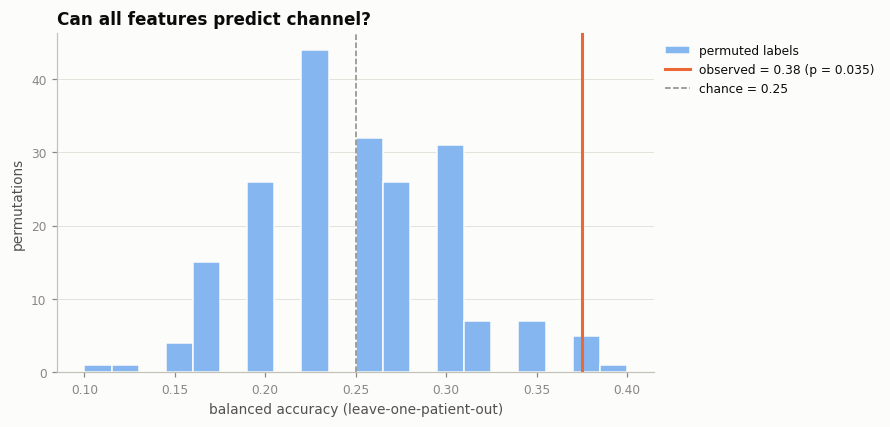

In [25]:
channel_cv, channel_null = classification_cv(table, info, target="channel", cv_groups="case", n_perm=200)
fig = plot_permutation_null(channel_cv, channel_null)
save_figure(fig, FIGURE_DIR / "classification_channel.png")

saved /Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs/figures/feature_analysis/classification_side.png


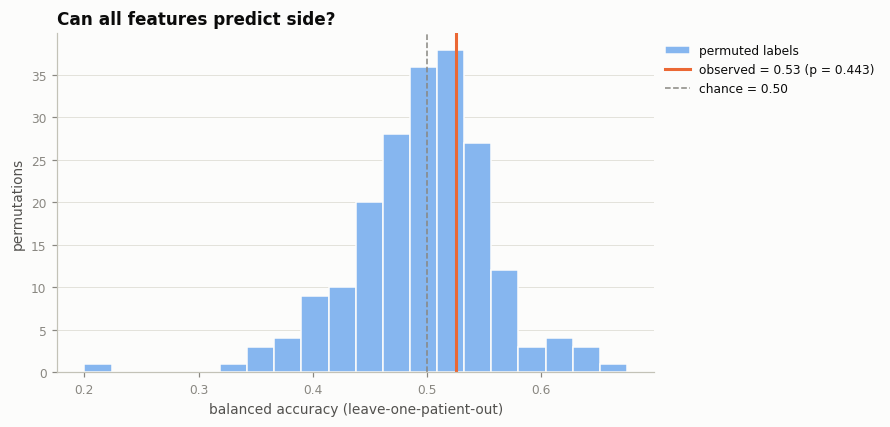

In [26]:
side_cv, side_null = classification_cv(table, info_no_shape, target="side", cv_groups="case", n_perm=200)
fig = plot_permutation_null(side_cv, side_null)
save_figure(fig, FIGURE_DIR / "classification_side.png")